In [17]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

import pandas as pd
import metrics
from io_utils import load_data
import viz
import analyzer
df = load_data()
health = analyzer.HealthAnalyzer(df)

In [18]:
import importlib
importlib.reload(analyzer)
importlib.reload(metrics)
importlib.reload(viz)


<module 'viz' from 'c:\\Users\\Lovisgaming\\Desktop\\ANALYS NY\\Health_Study_Analyze\\src\\viz.py'>

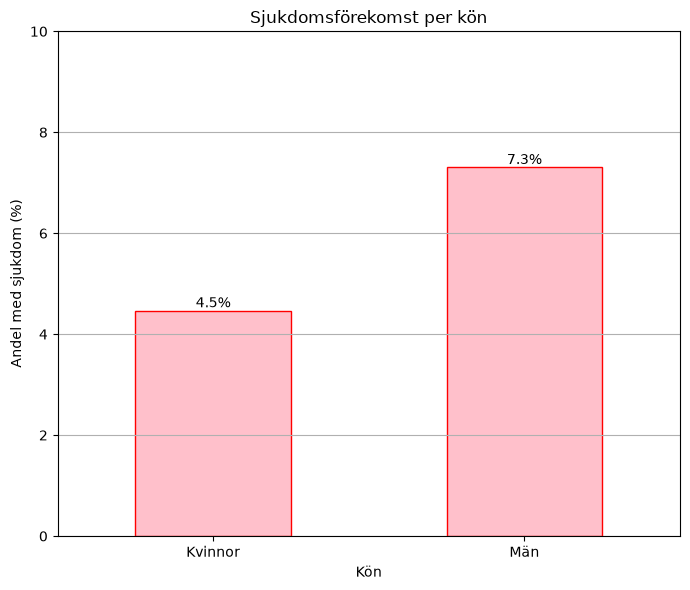

In [19]:
health.bar_disease_sex()

In [20]:
health.get_summary()

,age,weight,height,systolic_bp,cholesterol
count,800.000000,800.000000,800.000000,800.000000,800.000000
mean,49.426250,73.413000,171.849250,149.178625,4.929150
std,14.501118,13.685059,9.804259,12.793360,0.848413
min,18.000000,33.700000,144.400000,106.800000,2.500000
25%,39.000000,64.800000,164.775000,140.900000,4.327500
50%,50.000000,73.200000,171.350000,149.400000,4.970000
75%,59.000000,82.600000,178.925000,157.600000,5.482500
max,90.000000,114.400000,200.400000,185.900000,7.880000


In [21]:
slope, intercept = metrics.age_bp_regression(df)

print("Lutning:", slope)
print("Intercept:", intercept)

Lutning: 0.5360255996690318
Intercept: 122.6848897043585


In [22]:
health.get_summary()

,age,weight,height,systolic_bp,cholesterol
count,800.000000,800.000000,800.000000,800.000000,800.000000
mean,49.426250,73.413000,171.849250,149.178625,4.929150
std,14.501118,13.685059,9.804259,12.793360,0.848413
min,18.000000,33.700000,144.400000,106.800000,2.500000
25%,39.000000,64.800000,164.775000,140.900000,4.327500
50%,50.000000,73.200000,171.350000,149.400000,4.970000
75%,59.000000,82.600000,178.925000,157.600000,5.482500
max,90.000000,114.400000,200.400000,185.900000,7.880000


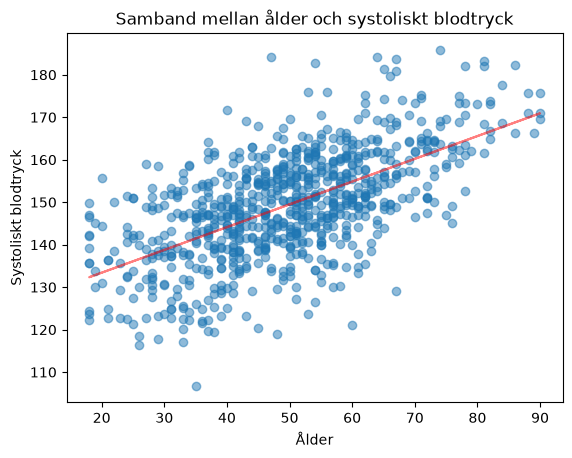

In [23]:
health.scat_age_bp()

In [24]:
disease_by_sex = metrics.disease_by_sex(df)

print(disease_by_sex)

sex
F    0.044665
M    0.073048
Name: disease, dtype: float64


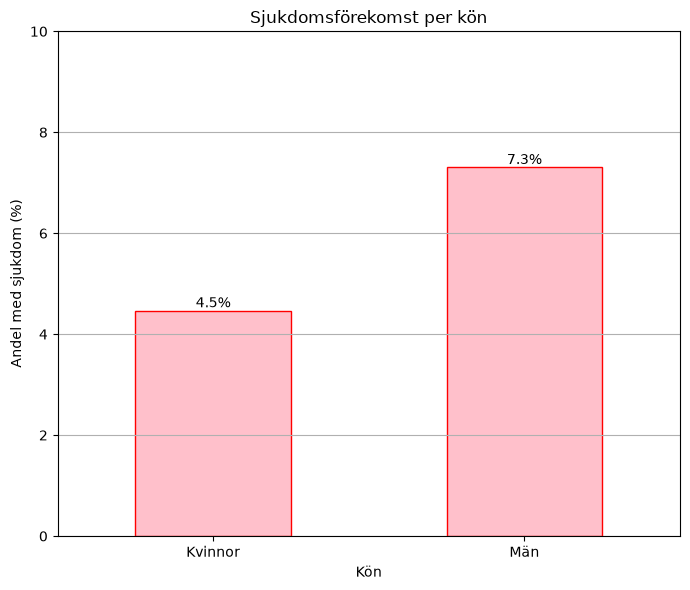

In [25]:
viz.bar_disease_sex(df)

In [26]:
print("Totalt antal celler:", len(In))
print("Antal kodceller:", len([x for x in In if x.strip()]))

Totalt antal celler: 27
Antal kodceller: 26


In [27]:
from pathlib import Path
import json

path = Path("del2.ipynb")

with open(path, encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        code = "".join(cell["source"]).strip()
        print(f"\n--- Cell {i} ---")
        print(code[:200])


--- Cell 0 ---
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

import pandas as pd
import metrics
from io_utils import load_data
import viz
import an

--- Cell 1 ---
import importlib
importlib.reload(analyzer)
importlib.reload(metrics)
importlib.reload(viz)

--- Cell 2 ---
health.bar_disease_sex()

--- Cell 3 ---
health.get_summary()

--- Cell 4 ---
slope, intercept = metrics.age_bp_regression(df)

print("Lutning:", slope)
print("Intercept:", intercept)

--- Cell 5 ---
health.get_summary()

--- Cell 6 ---
health.scat_age_bp()

--- Cell 7 ---
disease_by_sex = metrics.disease_by_sex(df)

print(disease_by_sex)

--- Cell 8 ---
viz.bar_disease_sex(df)

--- Cell 9 ---
print("Totalt antal celler:", len(In))
print("Antal kodceller:", len([x for x in In if x.strip()]))

--- Cell 10 ---
from pathlib import Path
import json

path = Path("del2.ipynb")

with open(path, encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell

In [28]:
for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        code = "".join(cell["source"]).strip()
        first_line = code.split("\n")[0] if code else "(tom cell)"
        print(f"Cell {i}: {first_line}")

Cell 0: import sys
Cell 1: import importlib
Cell 2: health.bar_disease_sex()
Cell 3: health.get_summary()
Cell 4: slope, intercept = metrics.age_bp_regression(df)
Cell 5: health.get_summary()
Cell 6: health.scat_age_bp()
Cell 7: disease_by_sex = metrics.disease_by_sex(df)
Cell 8: viz.bar_disease_sex(df)
Cell 9: print("Totalt antal celler:", len(In))
Cell 10: from pathlib import Path
Cell 11: for i, cell in enumerate(notebook["cells"]):


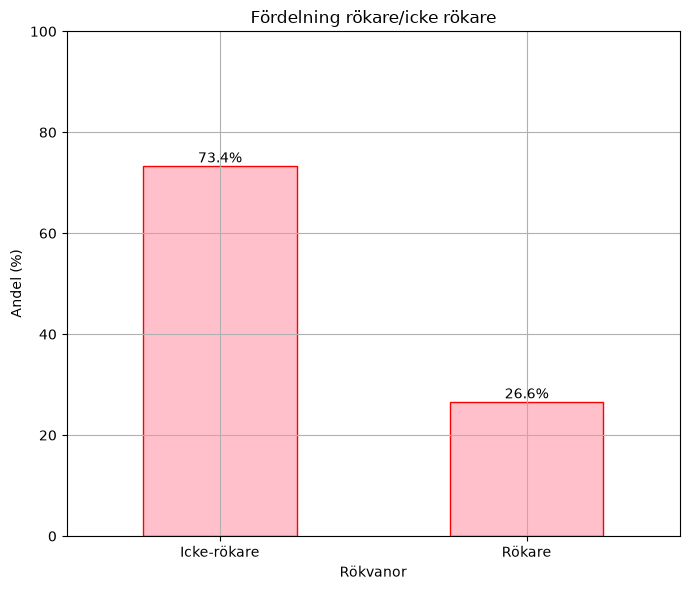

In [30]:
import matplotlib.pyplot as plt

smoker_percent = df["smoker"].value_counts(normalize=True) * 100
smoker_percent = smoker_percent.rename({
    "No": "Icke-rökare",
    "Yes": "Rökare"
})
smoker_percent.plot(
    kind="bar",
    color="pink",
    edgecolor="red",
    figsize=(7,6)
    )
plt.grid("y")
plt.title("Fördelning rökare/icke rökare")
plt.xlabel("Rökvanor")
plt.ylabel("Andel (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.bar_label(plt.gca().containers[0], fmt="%.1f%%")
plt.tight_layout()
plt.show()

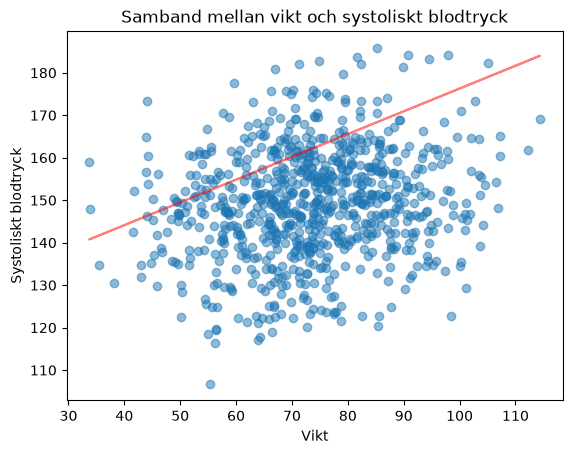

In [31]:
    plt.scatter(df["weight"], df["systolic_bp"], alpha=0.5)
    plt.title("Samband mellan vikt och systoliskt blodtryck")
    plt.xlabel("Vikt")
    plt.ylabel("Systoliskt blodtryck")

    slope, intercept = metrics.age_bp_regression(df)

    x = df["weight"]
    plt.plot(x, slope * x + intercept, color="red", alpha=0.5)

    plt.show()

In [ ]:
for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        code = "".join(cell["source"]).strip()
        first_line = code.split("\n")[0] if code else "(tom cell)"
        print(f"Cell {i}: {first_line}")

Cell 0: import sys
Cell 1: import importlib
Cell 2: health.bar_disease_sex()
Cell 3: health.get_summary()
Cell 4: slope, intercept = metrics.age_bp_regression(df)
Cell 5: health.get_summary()
Cell 6: health.scat_age_bp()
Cell 7: disease_by_sex = metrics.disease_by_sex(df)
Cell 8: viz.bar_disease_sex(df)
Cell 9: print("Totalt antal celler:", len(In))
Cell 10: from pathlib import Path
Cell 11: for i, cell in enumerate(notebook["cells"]):
